### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [3]:
def make_Dataset(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)

    return train_loader, x_val_tensor, y_val_tensor

In [4]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0

    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    tr_loss /= num_batches

    return tr_loss.item()

In [5]:
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, optimizer, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [6]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'Train Err', marker=',')
    plt.plot(epochs, val_loss_list, label= 'Val Err', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

In [21]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

# 이번 실습에 필요한 두 열만 사용
# df = df[["total_bill", "tip"]].dropna().copy()
data = pd.read_csv(url)
print(data.head())
feature = 'total_bill'
target = 'tip'
x = data.loc[:,[feature]]
y = data.loc[:, target]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size =.2)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
y_train = y_train.values
y_val = y_val.values

train_loader, x_val_tensor, y_val_tensor = make_Dataset(x_train, x_val, y_train, y_val, 32)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [11]:
# NOTE n_feature를 클래스 생성자의 매개변수로 받아서 nn.Linear()에 전달

class MLP(nn.Module):
    def __init__(self, n_feature):
        super().__init__()
        
        self.linear = nn.Linear(n_feature, 1)

    # 는 입력 데이터 x 가 모델안에서 어떤 계산을 거쳐서 예측값이 되는지 정의하는 함수
    def forward(self, x):
        x = self.linear(x)
        return x

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

In [13]:
LR = 1e-2
EPOCHS = 200

n_feature = x.shape[1]
model = MLP(n_feature)
loss_fn = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr = LR)

#### Step4. 모델 테스트하기


In [14]:
tr_loss_list, val_loss_list = [], []
for ep in range(EPOCHS):
    tr_loss = train(train_loader, model, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_tensor, y_val_tensor, model, loss_fn, optimizer, device) 
    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    print(f'Epoch: {ep+1}, Train Loss: {tr_loss}, Val Loss: {val_loss}')

Epoch: 1, Train Loss: 13.681747436523438, Val Loss: 14.100907325744629
Epoch: 2, Train Loss: 12.571354866027832, Val Loss: 10.670242309570312
Epoch: 3, Train Loss: 7.021206378936768, Val Loss: 8.518110275268555
Epoch: 4, Train Loss: 5.696560382843018, Val Loss: 6.8750081062316895
Epoch: 5, Train Loss: 4.668732166290283, Val Loss: 5.630253791809082
Epoch: 6, Train Loss: 3.593432903289795, Val Loss: 4.7183003425598145
Epoch: 7, Train Loss: 2.91768217086792, Val Loss: 4.028683185577393
Epoch: 8, Train Loss: 2.2838873863220215, Val Loss: 3.5632121562957764
Epoch: 9, Train Loss: 2.4030206203460693, Val Loss: 3.1275758743286133
Epoch: 10, Train Loss: 2.727736711502075, Val Loss: 2.7694668769836426
Epoch: 11, Train Loss: 1.6647919416427612, Val Loss: 2.545728921890259
Epoch: 12, Train Loss: 1.4479762315750122, Val Loss: 2.4004390239715576
Epoch: 13, Train Loss: 1.4698667526245117, Val Loss: 2.2672736644744873
Epoch: 14, Train Loss: 1.424325704574585, Val Loss: 2.207981586456299
Epoch: 15, Tra

#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

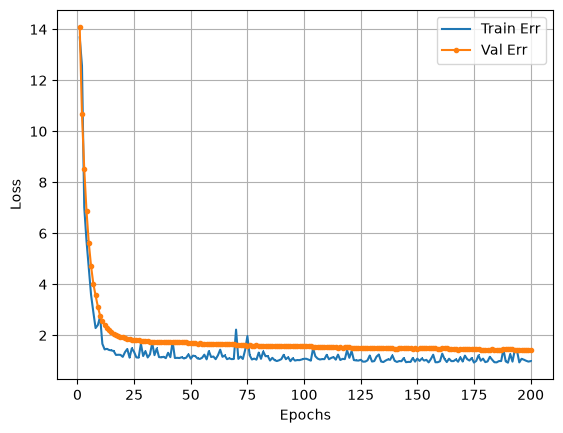

In [15]:
learning_curve(tr_loss_list, val_loss_list)

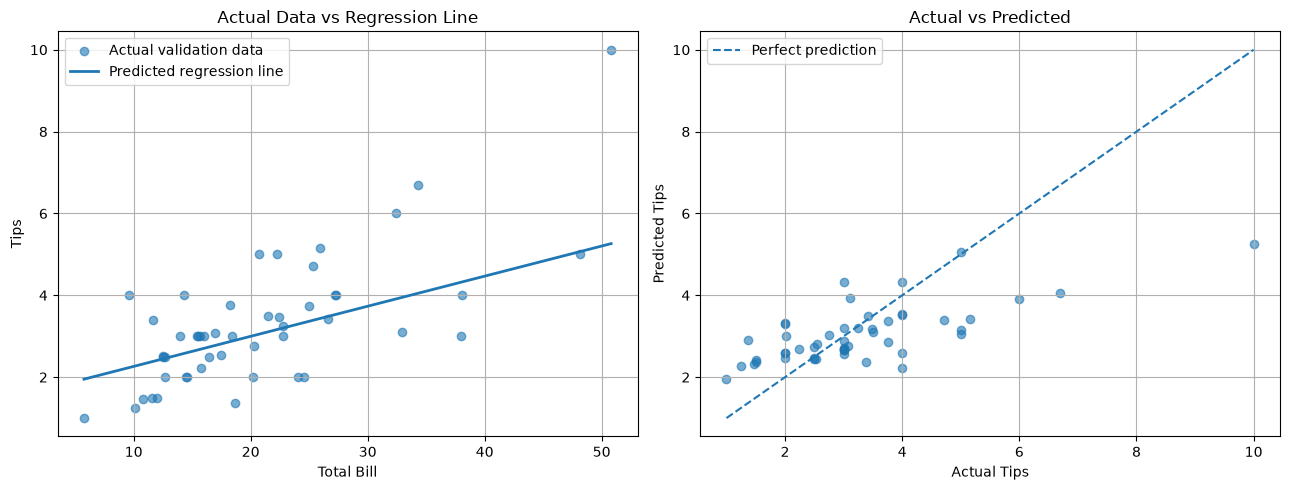

In [20]:
# 검증 데이터 예측
model.eval()
with torch.no_grad():
    pred = model(x_val_tensor.to(device))

# 그래프에 사용할 NumPy 배열로 변환
# .ravel() | 배열을 1차원으로 펼치는 NumPy 메서드
x_val_original = scaler.inverse_transform(
    x_val_tensor.cpu().numpy()
).ravel()

y_actual = y_val_tensor.cpu().numpy().ravel()
y_pred = pred.cpu().numpy().ravel()

# 원래 무게 기준으로 정렬
# 예측값도 동일한 인덱스로 정렬하여 대응 관계 유지
sort_idx = np.argsort(x_val_original)
x_sorted = x_val_original[sort_idx]
y_pred_sorted = y_pred[sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. 실제 검증 데이터와 예측 회귀선
axes[0].scatter(
    x_val_original,
    y_actual,
    alpha=0.6,
    label='Actual validation data'
)
axes[0].plot(
    x_sorted,
    y_pred_sorted,
    linewidth=2,
    label='Predicted regression line'
)
axes[0].set_xlabel('Total Bill')
axes[0].set_ylabel('Tips')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 2. 실제 연비와 예측 연비 비교
axes[1].scatter(y_actual, y_pred, alpha=0.6)

min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())

axes[1].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    label='Perfect prediction'
)
axes[1].set_xlabel('Actual Tips')
axes[1].set_ylabel('Predicted Tips')
axes[1].set_title('Actual vs Predicted')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인

In [19]:
# 전체 파라미터 개수
total_params = sum(p.numel() for p in model.parameters())

print(f'전체 파라미터: {total_params:,}개')     # 2 개 ( weight 1개 , bias 1개 )

전체 파라미터: 2개
